## 2. Imports and reproducibility

In [3]:

# Cell 1 — Imports and environment reproducibility

import importlib.metadata
import importlib.util
import sys
from pathlib import Path


def locate_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for candidate in (start, *start.parents):
        if (
            (candidate / "notebooks").is_dir()
            and (candidate / "requirements.txt").is_file()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root. "
        "Expected notebooks/ and requirements.txt."
    )


PROJECT_ROOT = locate_project_root()

EXPECTED_PYTHON = (
    PROJECT_ROOT / ".venv" / "bin" / "python"
).resolve()

ACTIVE_PYTHON = Path(sys.executable).resolve()

# Enforce the project's virtual environment.
if not EXPECTED_PYTHON.exists():
    raise RuntimeError(
        "Project virtual environment not found:\n"
        f"{EXPECTED_PYTHON}\n"
        "Create the .venv environment before continuing."
    )

if ACTIVE_PYTHON != EXPECTED_PYTHON:
    raise RuntimeError(
        "Incorrect notebook kernel.\n"
        f"Active: {ACTIVE_PYTHON}\n"
        f"Expected: {EXPECTED_PYTHON}\n"
        "In VS Code, select the project's .venv kernel."
    )


REQUIRED_IMPORTS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "pyarrow": "pyarrow",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "IPython": "IPython",
    "ipykernel": "ipykernel",
}

missing = [
    package
    for package, module in REQUIRED_IMPORTS.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    raise ModuleNotFoundError(
        "Missing packages: " + ", ".join(missing)
    )


print("Environment preflight: PASSED")
print("Project root:", PROJECT_ROOT)
print("Python:", ACTIVE_PYTHON)

for package in REQUIRED_IMPORTS:
    print(
        f"  {package}: "
        f"{importlib.metadata.version(package)}"
    )

Environment preflight: PASSED
Project root: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML
Python: /usr/bin/python3.12
  numpy: 2.5.4
  pandas: 3.0.6
  scipy: 1.18.1
  pyarrow: 26.0.0
  joblib: 1.6.0
  matplotlib: 3.11.2
  seaborn: 0.13.2
  scikit-learn: 1.9.1
  xgboost: 3.4.1
  IPython: 9.17.1
  ipykernel: 7.4.0


In [4]:
import json
import os
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from IPython.display import display

from sklearn.base import clone
from sklearn.feature_selection import (
    SelectKBest,
    SelectFromModel,
    RFE,
    f_classif,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


# Reproducibility
RANDOM_STATE = 42

# Nested cross-validation
N_OUTER_SPLITS = 5
N_INNER_SPLITS = 5

# Safety: final evaluation remains locked
RUN_FINAL_EVALUATION = False

# Local CPU configuration
N_JOBS = max(
    1,
    min(4, (os.cpu_count() or 2) - 1)
)

# Random seed
np.random.seed(RANDOM_STATE)

# Pandas
pd.set_option("display.max_columns", 120)

# Visualization
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Feature-selection methods
SELECTION_METHODS = [
    "Baseline",
    "SelectKBest",
    "L1",
    "RFE",
]

# Experiment settings
FEATURE_COUNTS = [50, 100, 200, 500]
L1_C_VALUES = [0.001, 0.01, 0.1, 1.0, 10.0]

print("E1 Feature Selection — Configuration")
print("-" * 45)
print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("Outer CV folds:", N_OUTER_SPLITS)
print("Inner CV folds:", N_INNER_SPLITS)
print("Random seed:", RANDOM_STATE)
print("CPU workers:", N_JOBS)
print("Final evaluation enabled:", RUN_FINAL_EVALUATION)

E1 Feature Selection — Configuration
---------------------------------------------
Python: 3.12.3
scikit-learn: 1.9.1
Outer CV folds: 5
Inner CV folds: 5
Random seed: 42
CPU workers: 4
Final evaluation enabled: False


## 3. Configuration and project paths

In [6]:
PROJECT_ROOT = PROJECT_ROOT.resolve()

# Input feature tables
FEATURE_ROOT = PROJECT_ROOT / "tuab_feature_extraction" / "features"

FE_ALL_PATH = FEATURE_ROOT / "tuab_recording_features.parquet"
FE_QC_PATH = FEATURE_ROOT / "tuab_recording_features_qc.parquet"

# Separate E1 outputs from existing ML baseline results
REPORT_ROOT = PROJECT_ROOT / "reports" / "feature_selection"
FIGURE_DIR = REPORT_ROOT / "figures"

RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

RUN_DIR = REPORT_ROOT / "runs" / RUN_ID

OUTPUT_DIRS = {
    "integrity": RUN_DIR / "integrity",
    "nested_cv": RUN_DIR / "nested_cv",
    "selection": RUN_DIR / "selected_features",
    "stability": RUN_DIR / "stability",
    "comparisons": RUN_DIR / "comparisons",
    "models": RUN_DIR / "models",
}

# Check input files before creating output directories
assert PROJECT_ROOT.is_dir(), (
    f"Missing project directory: {PROJECT_ROOT}"
)

assert FE_ALL_PATH.is_file(), (
    f"Missing FE-All table: {FE_ALL_PATH}"
)

assert FE_QC_PATH.is_file(), (
    f"Missing FE-QC table: {FE_QC_PATH}"
)

assert not RUN_DIR.exists(), (
    f"Run directory already exists: {RUN_DIR}"
)

# Create E1 output directories
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for directory in OUTPUT_DIRS.values():
    directory.mkdir(parents=True, exist_ok=False)

print("E1 paths: VERIFIED")
print("-" * 50)
print("Project root:", PROJECT_ROOT)
print("FE-All:", FE_ALL_PATH)
print("FE-QC:", FE_QC_PATH)
print("Run ID:", RUN_ID)
print("Run directory:", RUN_DIR)
print("CPU jobs:", N_JOBS)
print("Final evaluation enabled:", RUN_FINAL_EVALUATION)

E1 paths: VERIFIED
--------------------------------------------------
Project root: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML
FE-All: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/features/tuab_recording_features.parquet
FE-QC: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_feature_extraction/features/tuab_recording_features_qc.parquet
Run ID: 20261024T094237_544427Z
Run directory: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/runs/20261024T094237_544427Z
CPU jobs: 4
Final evaluation enabled: False


## 4. Inspect FE-All and FE-QC

In [7]:
fe_all = pd.read_parquet(FE_ALL_PATH)
fe_qc = pd.read_parquet(FE_QC_PATH)

print("=" * 60)
print("1. DATASET SHAPES")
print("=" * 60)

print("FE-All:", fe_all.shape)
print("FE-QC: ", fe_qc.shape)

print("\n" + "=" * 60)
print("2. COLUMN NAMES")
print("=" * 60)

print("\nFE-All — first 25 columns:")
print(fe_all.columns[:25].tolist())

print("\nFE-QC — first 25 columns:")
print(fe_qc.columns[:25].tolist())

print("\nFE-All — last 15 columns:")
print(fe_all.columns[-15:].tolist())

print("\nFE-QC — last 15 columns:")
print(fe_qc.columns[-15:].tolist())

print("\n" + "=" * 60)
print("3. METADATA CANDIDATES")
print("=" * 60)

keywords = [
    "patient", "subject", "label",
    "target", "split", "record",
    "epoch", "qc", "accepted",
    "path", "file"
]

for name, df in [("FE-All", fe_all), ("FE-QC", fe_qc)]:
    metadata = [
        col for col in df.columns
        if any(word in col.lower() for word in keywords)
    ]

    print(f"\n{name} — possible metadata columns:")
    print(metadata[:60])

print("\n" + "=" * 60)
print("4. MISSING VALUES")
print("=" * 60)

for name, df in [("FE-All", fe_all), ("FE-QC", fe_qc)]:
    missing_rows = df.isna().any(axis=1).sum()
    missing_columns = df.isna().any(axis=0).sum()

    print(f"\n{name}:")
    print("Rows containing NaN:", missing_rows)
    print("Columns containing NaN:", missing_columns)

print("\nSchema inspection: COMPLETE")

1. DATASET SHAPES
FE-All: (2993, 1156)
FE-QC:  (2993, 1159)

2. COLUMN NAMES

FE-All — first 25 columns:
['filepath', 'patient_id', 'label', 'split', 'car__C3__alpha_absolute_power__iqr', 'car__C3__alpha_absolute_power__median', 'car__C3__alpha_relative_power__iqr', 'car__C3__alpha_relative_power__median', 'car__C3__beta_absolute_power__iqr', 'car__C3__beta_absolute_power__median', 'car__C3__beta_relative_power__iqr', 'car__C3__beta_relative_power__median', 'car__C3__delta_absolute_power__iqr', 'car__C3__delta_absolute_power__median', 'car__C3__delta_alpha_ratio__iqr', 'car__C3__delta_alpha_ratio__median', 'car__C3__delta_relative_power__iqr', 'car__C3__delta_relative_power__median', 'car__C3__hjorth_complexity__iqr', 'car__C3__hjorth_complexity__median', 'car__C3__hjorth_mobility__iqr', 'car__C3__hjorth_mobility__median', 'car__C3__iqr__iqr', 'car__C3__iqr__median', 'car__C3__line_length__iqr']

FE-QC — first 25 columns:
['filepath', 'patient_id', 'label', 'split', 'total_epochs', 'ac

## 5. Dataset integrity and QC eligibility

In [ ]:
METADATA_COLS = [
    "filepath", "patient_id", "label", "split"
]

QC_COLS = [
    "total_epochs",
    "accepted_epochs",
    "accepted_fraction"
]

FEATURE_COLS = [
    col for col in fe_all.columns
    if col not in METADATA_COLS
]

# 1. Verify schemas and feature alignment
assert all(col in fe_all.columns for col in METADATA_COLS)
assert all(col in fe_qc.columns for col in METADATA_COLS + QC_COLS)

assert len(FEATURE_COLS) == 1152
assert len(FEATURE_COLS) == len(set(FEATURE_COLS))

assert fe_qc.columns.tolist() == (
    METADATA_COLS + QC_COLS + FEATURE_COLS
), "FE-QC feature columns or ordering differ from FE-All."

print("1. Feature schema: PASSED")
print("EEG feature count:", len(FEATURE_COLS))

# 2. Verify recording identity
for name, df in [("FE-All", fe_all), ("FE-QC", fe_qc)]:
    assert df["filepath"].notna().all()
    assert df["patient_id"].notna().all()
    assert df["label"].notna().all()
    assert df["split"].notna().all()
    assert df["filepath"].is_unique, f"Duplicate filepath in {name}"

all_metadata = fe_all[METADATA_COLS].sort_values(
    "filepath"
).reset_index(drop=True)

qc_metadata = fe_qc[METADATA_COLS].sort_values(
    "filepath"
).reset_index(drop=True)

pd.testing.assert_frame_equal(
    all_metadata,
    qc_metadata,
    check_dtype=False
)

print("\n2. Recording identity: PASSED")

# 3. QC eligibility
qc_eligible = fe_qc["accepted_epochs"].gt(0)

print("\n3. QC eligibility")
print("Eligible recordings:", int(qc_eligible.sum()))
print("Ineligible recordings:", int((~qc_eligible).sum()))

print("\nAccepted epochs summary:")
print(fe_qc["accepted_epochs"].describe())

# 4. Missing EEG features by QC eligibility
feature_missing = fe_qc[FEATURE_COLS].isna().any(axis=1)

print("\n4. Missing-feature consistency")
print(pd.crosstab(
    qc_eligible.rename("QC eligible"),
    feature_missing.rename("Has missing EEG features")
))

# 5. Split distribution
print("\n5. FE-QC split distribution")
print(pd.crosstab(
    fe_qc["split"],
    fe_qc["label"],
    margins=True
))

print("\n6. Eligible FE-QC split distribution")
print(pd.crosstab(
    fe_qc.loc[qc_eligible, "split"],
    fe_qc.loc[qc_eligible, "label"],
    margins=True
))

# 7. Patient independence
patient_sets = {
    split: set(group["patient_id"])
    for split, group in fe_qc.groupby("split")
}

print("\n7. Patient independence")

split_names = list(patient_sets)

for i, split_a in enumerate(split_names):
    for split_b in split_names[i + 1:]:
        overlap = patient_sets[split_a] & patient_sets[split_b]
        print(f"{split_a} vs {split_b}: {len(overlap)} overlapping patients")
        assert not overlap, "Patient leakage detected!"

print("\nCell 5 integrity checks: PASSED")

1. Feature schema: PASSED
EEG feature count: 1152

2. Recording identity: PASSED

3. QC eligibility
Eligible recordings: 2979
Ineligible recordings: 14

Accepted epochs summary:
count    2993.000000
mean      152.882392
std        59.187815
min         0.000000
25%       140.000000
50%       150.000000
75%       164.000000
max      1731.000000
Name: accepted_epochs, dtype: float64

4. Missing-feature consistency
Has missing EEG features  False  True 
QC eligible                           
False                         0     14
True                       2979      0

5. FE-QC split distribution
label  abnormal  normal   All
split                        
eval        126     150   276
train      1076    1097  2173
val         270     274   544
All        1472    1521  2993

6. Eligible FE-QC split distribution
label  abnormal  normal   All
split                        
eval        126     150   276
train      1068    1097  2165
val         266     272   538
All        1460    1519  2979



## 6. Prepare the E1 development dataset

In [9]:
# Keep only QC-eligible training recordings
e1_train = fe_qc.loc[
    (fe_qc["split"] == "train") &
    (fe_qc["accepted_epochs"] > 0)
].copy()

# Feature matrix: 1,152 EEG features
X_train = e1_train[FEATURE_COLS].copy()

# Binary labels
y_train = e1_train["label"].map({
    "normal": 0,
    "abnormal": 1,
})

# Patient grouping
groups_train = e1_train["patient_id"].copy()

# Integrity checks
assert X_train.shape == (2165, 1152)
assert y_train.notna().all()
assert set(y_train.unique()) == {0, 1}
assert groups_train.notna().all()
assert not X_train.isna().any().any()
assert np.isfinite(X_train.to_numpy()).all()

# Keep row indices aligned
X_train = X_train.reset_index(drop=True)
y_train = y_train.astype(int).reset_index(drop=True)
groups_train = groups_train.reset_index(drop=True)

print("E1 training data: READY")
print("-" * 45)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Patient groups:", groups_train.nunique())

print("\nClass distribution:")
print(y_train.value_counts().rename(index={
    0: "normal",
    1: "abnormal",
}))

print("\nFeature count:", len(FEATURE_COLS))
print("Validation/evaluation data used: NO")

E1 training data: READY
---------------------------------------------
X_train: (2165, 1152)
y_train: (2165,)
Patient groups: 1662

Class distribution:
label
normal      1097
abnormal    1068
Name: count, dtype: int64

Feature count: 1152
Validation/evaluation data used: NO


## 7. Verify nested CV feasibility

In [10]:
outer_cv = StratifiedGroupKFold(
    n_splits=N_OUTER_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

inner_cv = StratifiedGroupKFold(
    n_splits=N_INNER_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)

outer_splits = list(
    outer_cv.split(X_train, y_train, groups_train)
)

for outer_id, (train_idx, test_idx) in enumerate(
    outer_splits, start=1
):
    outer_train_patients = set(groups_train.iloc[train_idx])
    outer_test_patients = set(groups_train.iloc[test_idx])

    assert outer_train_patients.isdisjoint(outer_test_patients)
    assert y_train.iloc[train_idx].nunique() == 2
    assert y_train.iloc[test_idx].nunique() == 2

    X_outer = X_train.iloc[train_idx]
    y_outer = y_train.iloc[train_idx]
    groups_outer = groups_train.iloc[train_idx]

    inner_splits = list(
        inner_cv.split(X_outer, y_outer, groups_outer)
    )

    for inner_train_idx, inner_val_idx in inner_splits:
        inner_train_patients = set(
            groups_outer.iloc[inner_train_idx]
        )
        inner_val_patients = set(
            groups_outer.iloc[inner_val_idx]
        )

        assert inner_train_patients.isdisjoint(
            inner_val_patients
        )
        assert y_outer.iloc[inner_train_idx].nunique() == 2
        assert y_outer.iloc[inner_val_idx].nunique() == 2

    print(
        f"Outer fold {outer_id}: "
        f"train={len(train_idx)}, "
        f"test={len(test_idx)}, "
        f"inner folds={len(inner_splits)}, "
        f"patient overlap=0"
    )

print("\nNested CV structure: VERIFIED")
print("Model training performed: NO")


Outer fold 1: train=1731, test=434, inner folds=5, patient overlap=0
Outer fold 2: train=1731, test=434, inner folds=5, patient overlap=0
Outer fold 3: train=1733, test=432, inner folds=5, patient overlap=0
Outer fold 4: train=1733, test=432, inner folds=5, patient overlap=0
Outer fold 5: train=1732, test=433, inner folds=5, patient overlap=0

Nested CV structure: VERIFIED
Model training performed: NO


## 8. Baseline pipeline and hyperparameter search

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

baseline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=False,
        cache_size=500,
        random_state=RANDOM_STATE,
    )),
])

# Candidate hyperparameters for inner CV
baseline_param_grid = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": ["scale", 0.01, 0.001],
}

# Check the configuration without fitting
n_candidates = (
    len(baseline_param_grid["classifier__C"])
    * len(baseline_param_grid["classifier__gamma"])
)

print("Experiment: E1-00")
print("Classifier: RBF SVM")
print("Feature count:", X_train.shape[1])
print("Outer folds:", N_OUTER_SPLITS)
print("Inner folds:", N_INNER_SPLITS)
print("Hyperparameter candidates:", n_candidates)
print("Inner-CV fits per outer fold:", n_candidates * N_INNER_SPLITS)
print("Pipeline:")
print(baseline_pipeline)

Experiment: E1-00
Classifier: RBF SVM
Feature count: 1152
Outer folds: 5
Inner folds: 5
Hyperparameter candidates: 9
Inner-CV fits per outer fold: 45
Pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SVC(cache_size=500, class_weight='balanced', probability=False,
                     random_state=42))])


## 9. Execute nested CV for E1-00

In [12]:
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

baseline_results = []
baseline_oof_predictions = []

for fold_id, (train_idx, test_idx) in enumerate(
    outer_splits, start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_test = X_train.iloc[test_idx]

    y_outer_train = y_train.iloc[train_idx]
    y_outer_test = y_train.iloc[test_idx]

    groups_outer_train = groups_train.iloc[train_idx]

    search = GridSearchCV(
        estimator=clone(baseline_pipeline),
        param_grid=baseline_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=N_JOBS,
        refit=True,
        error_score="raise",
    )

    search.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    best_model = search.best_estimator_

    scores = best_model.decision_function(X_outer_test)
    auc = roc_auc_score(y_outer_test, scores)

    baseline_results.append({
        "fold": fold_id,
        "roc_auc": auc,
        "best_C": search.best_params_["classifier__C"],
        "best_gamma": search.best_params_["classifier__gamma"],
        "inner_cv_auc": search.best_score_,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
    })

    baseline_oof_predictions.append(
        pd.DataFrame({
            "fold": fold_id,
            "patient_id": groups_train.iloc[test_idx].to_numpy(),
            "y_true": y_outer_test.to_numpy(),
            "score": scores,
        })
    )

    print(
        f"Fold {fold_id}: "
        f"AUC={auc:.4f} | "
        f"C={search.best_params_['classifier__C']} | "
        f"gamma={search.best_params_['classifier__gamma']}"
    )

baseline_results_df = pd.DataFrame(baseline_results)

baseline_oof_df = pd.concat(
    baseline_oof_predictions,
    ignore_index=True
)

print("\nE1-00 Nested CV Results")
display(baseline_results_df)

print(
    "\nMean outer-fold ROC-AUC:",
    round(baseline_results_df["roc_auc"].mean(), 4)
)

print(
    "Std outer-fold ROC-AUC:",
    round(baseline_results_df["roc_auc"].std(), 4)
)

# Save results
baseline_results_df.to_csv(
    OUTPUT_DIRS["nested_cv"] / "E1-00_outer_results.csv",
    index=False,
)

baseline_oof_df.to_parquet(
    OUTPUT_DIRS["nested_cv"] / "E1-00_oof_predictions.parquet",
    index=False,
)

/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 1: AUC=0.9236 | C=1.0 | gamma=scale


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 2: AUC=0.9022 | C=1.0 | gamma=scale


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


...

Fold 4: AUC=0.9218 | C=1.0 | gamma=scale


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 5: AUC=0.9165 | C=1.0 | gamma=scale

E1-00 Nested CV Results


,fold,roc_auc,best_C,best_gamma,inner_cv_auc,n_train,n_test
0,1,0.923577,1.0,scale,0.906078,1731,434
1,2,0.902230,1.0,scale,0.911845,1731,434
2,3,0.901966,10.0,scale,0.914416,1733,432
3,4,0.921796,1.0,scale,0.909672,1733,432
4,5,0.916507,1.0,scale,0.911584,1732,433



Mean outer-fold ROC-AUC: 0.9132
Std outer-fold ROC-AUC: 0.0105


## 10. Investigate mixed-label patients

In [ ]:
patient_summary = (
    baseline_oof_df
    .groupby("patient_id")
    .agg(
        n_recordings=("y_true", "size"),
        n_labels=("y_true", "nunique"),
        n_folds=("fold", "nunique"),
        normal_recordings=("y_true", lambda x: (x == 0).sum()),
        abnormal_recordings=("y_true", lambda x: (x == 1).sum()),
    )
    .reset_index()
)

mixed_patients = patient_summary[
    patient_summary["n_labels"] > 1
].copy()

print("=" * 55)
print("PATIENT-LABEL CONSISTENCY")
print("=" * 55)

print("Total patients:", len(patient_summary))
print("Patients with one label:",
      (patient_summary["n_labels"] == 1).sum())
print("Patients with mixed labels:", len(mixed_patients))

print("\nRecordings from mixed-label patients:",
      mixed_patients["n_recordings"].sum())

print("\nPatient overlap across outer folds:",
      (patient_summary["n_folds"] > 1).sum())

print("\nMixed-label patient examples:")
display(mixed_patients.head(10))

print("\nRecording distribution:")
display(patient_summary["n_recordings"].describe())

assert (patient_summary["n_folds"] == 1).all(), (
    "Patient leakage across outer folds detected!"
)

PATIENT-LABEL CONSISTENCY
Total patients: 1662
Patients with one label: 1621
Patients with mixed labels: 41

Recordings from mixed-label patients: 113

Patient overlap across outer folds: 0

Mixed-label patient examples:


,patient_id,n_recordings,n_labels,n_folds,normal_recordings,abnormal_recordings
15,aaaaaanr,2,2,1,1,1
39,aaaaabjt,3,2,1,2,1
137,aaaaaflq,2,2,1,1,1
197,aaaaaibr,2,2,1,1,1
199,aaaaaicb,2,2,1,1,1
219,aaaaaisv,2,2,1,1,1
227,aaaaaixl,2,2,1,1,1
229,aaaaaiyg,2,2,1,1,1
249,aaaaajez,4,2,1,1,3
259,aaaaajik,2,2,1,1,1



Recording distribution:


count    1662.000000
mean        1.302647
std         0.749380
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         9.000000
Name: n_recordings, dtype: float64

## 10B. Save the corrected baseline evaluation

In [ ]:
# Every recording must have exactly one OOF prediction
assert len(baseline_oof_df) == len(X_train)

# Check prediction labels and patient IDs against original rows
expected_pairs = pd.DataFrame({
    "patient_id": groups_train.to_numpy(),
    "y_true": y_train.to_numpy(),
})

actual_pairs = baseline_oof_df[
    ["patient_id", "y_true"]
]

expected_counts = expected_pairs.value_counts().sort_index()
actual_counts = actual_pairs.value_counts().sort_index()

pd.testing.assert_series_equal(
    expected_counts,
    actual_counts,
    check_names=False,
)

# Patient independence across outer folds
assert (
    baseline_oof_df.groupby("patient_id")["fold"].nunique()
    == 1
).all()

# Summary
print("E1-00 BASELINE — FINALIZED")
print("-" * 45)

print("Recordings:", len(baseline_oof_df))
print("Patients:", baseline_oof_df["patient_id"].nunique())

print(
    "Mean outer-fold ROC-AUC:",
    round(baseline_results_df["roc_auc"].mean(), 4)
)

print(
    "Std outer-fold ROC-AUC:",
    round(baseline_results_df["roc_auc"].std(), 4)
)

print("Patient overlap:", 0)
print("Evaluation unit: recording")
print("Grouping unit: patient")

# Save evaluation metadata
evaluation_protocol = {
    "experiment": "E1",
    "baseline": "E1-00",
    "evaluation_unit": "recording",
    "grouping_unit": "patient",
    "primary_metric": "roc_auc",
    "outer_folds": N_OUTER_SPLITS,
    "inner_folds": N_INNER_SPLITS,
    "random_state": RANDOM_STATE,
    "feature_count": len(FEATURE_COLS),
    "mixed_label_patients": len(mixed_patients),
    "final_evaluation_used": False,
}

protocol_path = (
    OUTPUT_DIRS["integrity"] /
    "evaluation_protocol.json"
)

with open(protocol_path, "w") as f:
    json.dump(evaluation_protocol, f, indent=2)

print("\nEvaluation protocol saved:", protocol_path)

E1-00 BASELINE — FINALIZED
---------------------------------------------
Recordings: 2165
Patients: 1662
Mean outer-fold ROC-AUC: 0.9132
Std outer-fold ROC-AUC: 0.0105
Patient overlap: 0
Evaluation unit: recording
Grouping unit: patient

Evaluation protocol saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/runs/20261024T094237_544427Z/integrity/evaluation_protocol.json


## 11. SelectKBest pipeline

In [17]:
from sklearn.feature_selection import SelectKBest, f_classif

selectkbest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif)),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=False,
        cache_size=500,
        random_state=RANDOM_STATE,
    )),
])

selectkbest_param_grid = {
    "selector__k": [50, 100, 200, 500],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": ["scale", 0.01, 0.001],
}

n_candidates = (
    len(selectkbest_param_grid["selector__k"])
    * len(selectkbest_param_grid["classifier__C"])
    * len(selectkbest_param_grid["classifier__gamma"])
)

print("Experiment: E1-01")
print("Method: SelectKBest (ANOVA F-score)")
print("Classifier: RBF SVM")
print("Feature candidates:", selectkbest_param_grid["selector__k"])
print("Hyperparameter combinations:", n_candidates)
print("Inner CV fits per outer fold:", n_candidates * N_INNER_SPLITS)
print("Outer folds:", N_OUTER_SPLITS)
print("Final evaluation enabled:", RUN_FINAL_EVALUATION)


Experiment: E1-01
Method: SelectKBest (ANOVA F-score)
Classifier: RBF SVM
Feature candidates: [50, 100, 200, 500]
Hyperparameter combinations: 36
Inner CV fits per outer fold: 180
Outer folds: 5
Final evaluation enabled: False


## 12. Run nested CV for SelectKBest

In [18]:
selectkbest_results = []
selectkbest_oof_predictions = []
selectkbest_selected_features = []

for fold_id, (train_idx, test_idx) in enumerate(
    outer_splits, start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_test = X_train.iloc[test_idx]

    y_outer_train = y_train.iloc[train_idx]
    y_outer_test = y_train.iloc[test_idx]

    groups_outer_train = groups_train.iloc[train_idx]

    search = GridSearchCV(
        estimator=clone(selectkbest_pipeline),
        param_grid=selectkbest_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=N_JOBS,
        refit=True,
        error_score="raise",
    )

    search.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    best_model = search.best_estimator_
    scores = best_model.decision_function(X_outer_test)

    auc = roc_auc_score(y_outer_test, scores)

    selected_mask = (
        best_model.named_steps["selector"].get_support()
    )

    selected_names = np.array(FEATURE_COLS)[selected_mask]

    selectkbest_results.append({
        "fold": fold_id,
        "roc_auc": auc,
        "best_k": search.best_params_["selector__k"],
        "best_C": search.best_params_["classifier__C"],
        "best_gamma": search.best_params_["classifier__gamma"],
        "inner_cv_auc": search.best_score_,
        "n_selected": len(selected_names),
        "n_train": len(train_idx),
        "n_test": len(test_idx),
    })

    selectkbest_oof_predictions.append(
        pd.DataFrame({
            "fold": fold_id,
            "filepath": e1_train.iloc[test_idx]["filepath"].to_numpy(),
            "patient_id": groups_train.iloc[test_idx].to_numpy(),
            "y_true": y_outer_test.to_numpy(),
            "score": scores,
        })
    )

    selectkbest_selected_features.append({
        "fold": fold_id,
        "features": selected_names.tolist(),
    })

    print(
        f"Fold {fold_id}: "
        f"AUC={auc:.4f} | "
        f"K={len(selected_names)} | "
        f"C={search.best_params_['classifier__C']} | "
        f"gamma={search.best_params_['classifier__gamma']}"
    )

selectkbest_results_df = pd.DataFrame(selectkbest_results)

selectkbest_oof_df = pd.concat(
    selectkbest_oof_predictions,
    ignore_index=True
)

print("\nE1-01 Nested CV Results")
display(selectkbest_results_df)

print(
    "\nMean outer-fold ROC-AUC:",
    round(selectkbest_results_df["roc_auc"].mean(), 4)
)

print(
    "Std outer-fold ROC-AUC:",
    round(selectkbest_results_df["roc_auc"].std(), 4)
)

# Save results
selectkbest_results_df.to_csv(
    OUTPUT_DIRS["nested_cv"] / "E1-01_outer_results.csv",
    index=False,
)

selectkbest_oof_df.to_parquet(
    OUTPUT_DIRS["nested_cv"] / "E1-01_oof_predictions.parquet",
    index=False,
)

with open(
    OUTPUT_DIRS["selection"] / "E1-01_selected_features.json",
    "w"
) as f:
    json.dump(selectkbest_selected_features, f, indent=2)


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 1: AUC=0.9339 | K=500 | C=10.0 | gamma=0.001


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 2: AUC=0.9067 | K=500 | C=10.0 | gamma=0.001


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


...

Fold 4: AUC=0.9309 | K=500 | C=10.0 | gamma=0.001


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


Fold 5: AUC=0.9270 | K=500 | C=10.0 | gamma=0.001

E1-01 Nested CV Results


,fold,roc_auc,best_k,best_C,best_gamma,inner_cv_auc,n_selected,n_train,n_test
0,1,0.933900,500,10.0,0.001,0.909612,500,1731,434
1,2,0.906691,500,10.0,0.001,0.915153,500,1731,434
2,3,0.894398,500,10.0,0.001,0.919685,500,1733,432
3,4,0.930885,500,10.0,0.001,0.909065,500,1733,432
4,5,0.927026,500,10.0,0.001,0.914567,500,1732,433



Mean outer-fold ROC-AUC: 0.9186
Std outer-fold ROC-AUC: 0.0172


## 13. Paired AUC comparison

In [19]:
# Add stable recording identity to baseline OOF predictions
baseline_with_ids = baseline_oof_df.copy()

baseline_with_ids["filepath"] = [
    e1_train.iloc[test_idx]["filepath"].iloc[j]
    for _, (_, test_idx) in enumerate(outer_splits)
    for j in range(len(test_idx))
]

baseline_with_ids = baseline_with_ids.rename(
    columns={"score": "baseline_score"}
)

selected_with_ids = selectkbest_oof_df.rename(
    columns={"score": "selected_score"}
)

paired = baseline_with_ids.merge(
    selected_with_ids[
        ["filepath", "patient_id", "y_true", "fold", "selected_score"]
    ],
    on=["filepath", "patient_id", "y_true", "fold"],
    how="inner",
    validate="one_to_one",
)

assert len(paired) == len(X_train)
assert paired["filepath"].is_unique

# Observed pooled recording-level difference
observed_delta = (
    roc_auc_score(paired["y_true"], paired["selected_score"])
    - roc_auc_score(paired["y_true"], paired["baseline_score"])
)

# Patient-clustered paired bootstrap
rng = np.random.default_rng(RANDOM_STATE)
patients = paired["patient_id"].unique()

patient_rows = {
    patient: group.index.to_numpy()
    for patient, group in paired.groupby("patient_id")
}

bootstrap_deltas = []

for _ in range(2000):
    sampled_patients = rng.choice(
        patients,
        size=len(patients),
        replace=True,
    )

    sampled_idx = np.concatenate([
        patient_rows[p] for p in sampled_patients
    ])

    sample = paired.loc[sampled_idx]

    if sample["y_true"].nunique() < 2:
        continue

    delta = (
        roc_auc_score(sample["y_true"], sample["selected_score"])
        - roc_auc_score(sample["y_true"], sample["baseline_score"])
    )

    bootstrap_deltas.append(delta)

ci_lower, ci_upper = np.percentile(
    bootstrap_deltas, [2.5, 97.5]
)

print("Paired recording-level comparison")
print("-" * 45)
print("Matched recordings:", len(paired))
print("Matched patients:", paired["patient_id"].nunique())
print(f"Pooled OOF AUC difference: {observed_delta:+.5f}")
print(f"95% patient-clustered bootstrap CI: [{ci_lower:+.5f}, {ci_upper:+.5f}]")

if ci_lower <= 0 <= ci_upper:
    print("Interpretation: CI includes zero.")
else:
    print("Interpretation: CI excludes zero.")

Paired recording-level comparison
---------------------------------------------
Matched recordings: 2165
Matched patients: 1662
Pooled OOF AUC difference: +0.00487
95% patient-clustered bootstrap CI: [-0.00082, +0.01093]
Interpretation: CI includes zero.


## 14. E1-01 Results Visualization

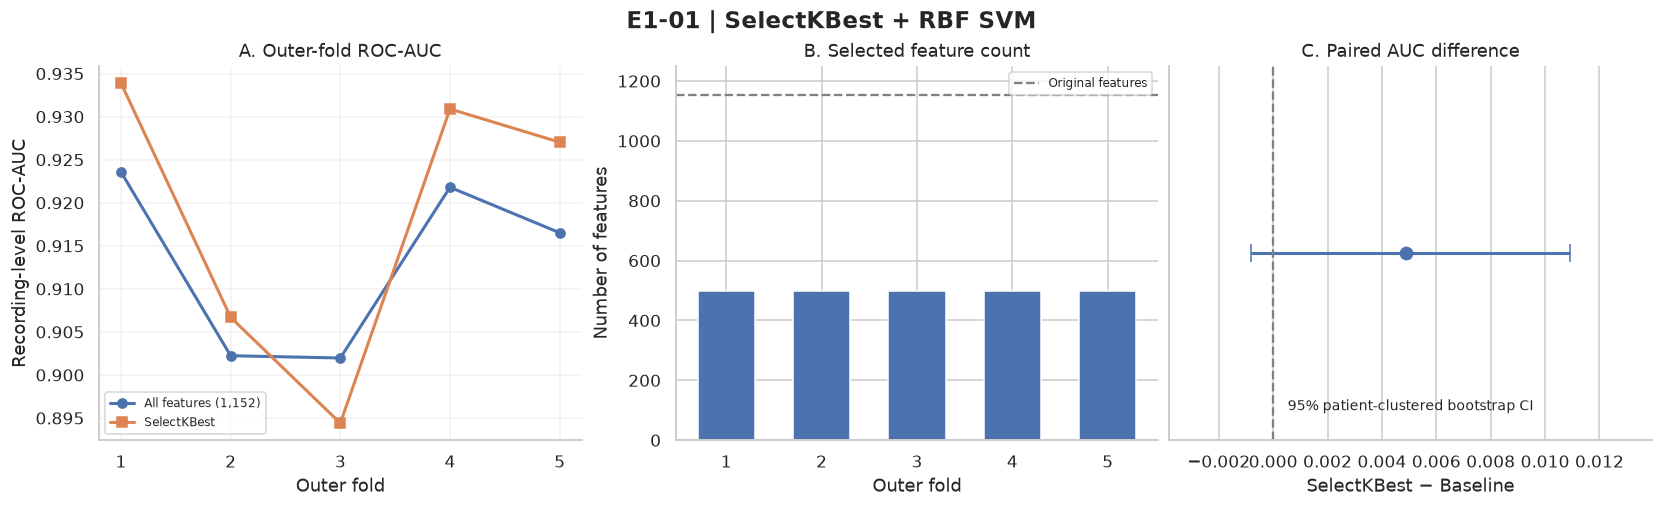

Figures saved:
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/figures/E1-01_SelectKBest_Results.png
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/figures/E1-01_SelectKBest_Results.pdf


In [ ]:
from matplotlib.lines import Line2D

baseline_auc = baseline_results_df.sort_values("fold")
selected_auc = selectkbest_results_df.sort_values("fold")

assert baseline_auc["fold"].tolist() == selected_auc["fold"].tolist()

folds = baseline_auc["fold"].to_numpy()
auc_baseline = baseline_auc["roc_auc"].to_numpy()
auc_selected = selected_auc["roc_auc"].to_numpy()

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5),
    constrained_layout=True
)

# A — Performance across outer folds
ax = axes[0]

ax.plot(
    folds, auc_baseline,
    marker="o", linewidth=2,
    label="All features (1,152)"
)
ax.plot(
    folds, auc_selected,
    marker="s", linewidth=2,
    label="SelectKBest"
)

ax.set(
    title="A. Outer-fold ROC-AUC",
    xlabel="Outer fold",
    ylabel="Recording-level ROC-AUC"
)
ax.set_xticks(folds)
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

# B — Selected feature counts
ax = axes[1]

ax.bar(
    folds,
    selected_auc["n_selected"],
    width=0.6
)

ax.axhline(
    1152,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Original features"
)

ax.set(
    title="B. Selected feature count",
    xlabel="Outer fold",
    ylabel="Number of features"
)
ax.set_xticks(folds)
ax.set_ylim(0, 1250)
ax.legend(fontsize=8)

# C — Paired pooled AUC improvement
ax = axes[2]

ax.errorbar(
    observed_delta,
    0,
    xerr=np.array([
        [observed_delta - ci_lower],
        [ci_upper - observed_delta]
    ]),
    fmt="o",
    capsize=6,
    markersize=8,
    linewidth=2
)

ax.axvline(
    0, color="gray",
    linestyle="--",
    linewidth=1.5
)

ax.set(
    title="C. Paired AUC difference",
    xlabel="SelectKBest − Baseline",
    yticks=[]
)

ax.set_xlim(
    min(ci_lower, 0) - 0.003,
    max(ci_upper, 0) + 0.003
)

ax.text(
    0.5, 0.08,
    "95% patient-clustered bootstrap CI",
    transform=ax.transAxes,
    ha="center",
    fontsize=9
)

fig.suptitle(
    "E1-01 | SelectKBest + RBF SVM",
    fontsize=15,
    fontweight="bold"
)

# Save publication-quality figures
figure_path = FIGURE_DIR / "E1-01_SelectKBest_Results"

fig.savefig(
    figure_path.with_suffix(".png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_path.with_suffix(".pdf"),
    bbox_inches="tight"
)

plt.show()

print("Figures saved:")
print(figure_path.with_suffix(".png"))
print(figure_path.with_suffix(".pdf"))

## 15. L1 pipeline configuration

In [21]:
from sklearn.feature_selection import SelectFromModel

l1_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),

    ("selector", SelectFromModel(
        estimator=LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        threshold=1e-8,
    )),

    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=False,
        cache_size=500,
        random_state=RANDOM_STATE,
    )),
])

# L1 strength and SVM hyperparameters
l1_param_grid = {
    "selector__estimator__C": [
        0.001, 0.01, 0.1, 1.0, 10.0
    ],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": [
        "scale", 0.01, 0.001
    ],
}

n_candidates = (
    len(l1_param_grid["selector__estimator__C"])
    * len(l1_param_grid["classifier__C"])
    * len(l1_param_grid["classifier__gamma"])
)

print("Experiment: E1-02")
print("Method: L1 Logistic Regression")
print("Classifier: RBF SVM")
print("Original features:", X_train.shape[1])
print("L1 C candidates:", l1_param_grid["selector__estimator__C"])
print("Hyperparameter combinations:", n_candidates)
print("Inner CV fits per outer fold:", n_candidates * N_INNER_SPLITS)
print("Outer folds:", N_OUTER_SPLITS)
print("Final evaluation enabled:", RUN_FINAL_EVALUATION)

Experiment: E1-02
Method: L1 Logistic Regression
Classifier: RBF SVM
Original features: 1152
L1 C candidates: [0.001, 0.01, 0.1, 1.0, 10.0]
Hyperparameter combinations: 45
Inner CV fits per outer fold: 225
Outer folds: 5
Final evaluation enabled: False


## 16. Check that candidate settings select features

In [22]:
from sklearn.exceptions import ConvergenceWarning
import warnings

l1_selection_counts = []

for c_value in l1_param_grid["selector__estimator__C"]:

    selector_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("selector", SelectFromModel(
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=c_value,
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
            threshold=1e-8,
        )),
    ])

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        selector_pipeline.fit(X_train, y_train)

    n_selected = int(
        selector_pipeline.named_steps["selector"]
        .get_support().sum()
    )

    l1_selection_counts.append({
        "l1_C": c_value,
        "n_selected": n_selected,
        "convergence_warnings": sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        ),
    })

l1_selection_counts_df = pd.DataFrame(
    l1_selection_counts
)

display(l1_selection_counts_df)

print(
    "Zero-feature candidates:",
    l1_selection_counts_df.loc[
        l1_selection_counts_df["n_selected"] == 0,
        "l1_C"
    ].tolist()
)

,l1_C,n_selected,convergence_warnings
0,0.001,0,0
1,0.010,18,0
2,0.100,112,0
3,1.000,440,0
4,10.000,717,0


Zero-feature candidates: [0.001]


## 17. Verify L1 feasibility inside every inner fold

In [23]:
SAFE_L1_C_VALUES = [0.01, 0.1, 1.0, 10.0]

l1_fold_checks = []

for outer_id, (outer_train_idx, _) in enumerate(
    outer_splits, start=1
):
    X_outer = X_train.iloc[outer_train_idx]
    y_outer = y_train.iloc[outer_train_idx]
    groups_outer = groups_train.iloc[outer_train_idx]

    for inner_id, (inner_train_idx, _) in enumerate(
        inner_cv.split(X_outer, y_outer, groups_outer),
        start=1
    ):
        X_inner = X_outer.iloc[inner_train_idx]
        y_inner = y_outer.iloc[inner_train_idx]

        for c_value in SAFE_L1_C_VALUES:
            selector_model = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("selector", SelectFromModel(
                    LogisticRegression(
                        penalty="l1",
                        solver="liblinear",
                        C=c_value,
                        max_iter=5000,
                        random_state=RANDOM_STATE,
                    ),
                    threshold=1e-8,
                )),
            ])

            selector_model.fit(X_inner, y_inner)

            n_selected = int(
                selector_model.named_steps["selector"]
                .get_support().sum()
            )

            l1_fold_checks.append({
                "outer_fold": outer_id,
                "inner_fold": inner_id,
                "l1_C": c_value,
                "n_selected": n_selected,
            })

l1_fold_checks_df = pd.DataFrame(l1_fold_checks)

summary = (
    l1_fold_checks_df.groupby("l1_C")["n_selected"]
    .agg(["min", "median", "max"])
)

display(summary)

assert (l1_fold_checks_df["n_selected"] > 0).all(), (
    "At least one candidate produces an empty feature subset."
)

print("L1 inner-fold feasibility: PASSED")
print("Selector fits checked:", len(l1_fold_checks_df))

/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in

,min,median,max
l1_C,,,
0.01,11,14.0,18
0.10,69,83.0,93
1.00,323,339.0,374
10.00,459,512.0,642


L1 inner-fold feasibility: PASSED
Selector fits checked: 100


## 18. E1-02 L1 Logistic Regression + RBF SVM 

In [24]:
l1_param_grid = {
    "selector__estimator__C": SAFE_L1_C_VALUES,
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": ["scale", 0.01, 0.001],
}

l1_results = []
l1_oof_predictions = []
l1_selected_features = []

for fold_id, (train_idx, test_idx) in enumerate(
    outer_splits, start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_test = X_train.iloc[test_idx]

    y_outer_train = y_train.iloc[train_idx]
    y_outer_test = y_train.iloc[test_idx]

    groups_outer_train = groups_train.iloc[train_idx]

    search = GridSearchCV(
        estimator=clone(l1_pipeline),
        param_grid=l1_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=N_JOBS,
        refit=True,
        error_score="raise",
    )

    start_time = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    elapsed = time.perf_counter() - start_time

    best_model = search.best_estimator_

    scores = best_model.decision_function(
        X_outer_test
    )

    auc = roc_auc_score(
        y_outer_test,
        scores
    )

    selected_mask = (
        best_model.named_steps["selector"]
        .get_support()
    )

    selected_names = np.asarray(
        FEATURE_COLS
    )[selected_mask]

    l1_results.append({
        "fold": fold_id,
        "roc_auc": auc,
        "best_l1_C": search.best_params_[
            "selector__estimator__C"
        ],
        "best_svm_C": search.best_params_[
            "classifier__C"
        ],
        "best_gamma": search.best_params_[
            "classifier__gamma"
        ],
        "inner_cv_auc": search.best_score_,
        "n_selected": len(selected_names),
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "runtime_seconds": elapsed,
    })

    l1_oof_predictions.append(
        pd.DataFrame({
            "fold": fold_id,
            "filepath": e1_train.iloc[test_idx][
                "filepath"
            ].to_numpy(),
            "patient_id": groups_train.iloc[
                test_idx
            ].to_numpy(),
            "y_true": y_outer_test.to_numpy(),
            "score": scores,
        })
    )

    l1_selected_features.append({
        "fold": fold_id,
        "l1_C": search.best_params_[
            "selector__estimator__C"
        ],
        "features": selected_names.tolist(),
    })

    print(
        f"Fold {fold_id}: "
        f"AUC={auc:.4f} | "
        f"Features={len(selected_names)} | "
        f"L1 C={search.best_params_['selector__estimator__C']} | "
        f"SVM C={search.best_params_['classifier__C']} | "
        f"gamma={search.best_params_['classifier__gamma']} | "
        f"time={elapsed:.1f}s"
    )

l1_results_df = pd.DataFrame(l1_results)

l1_oof_df = pd.concat(
    l1_oof_predictions,
    ignore_index=True
)

# Integrity checks
assert len(l1_oof_df) == len(X_train)
assert l1_oof_df["filepath"].is_unique

assert (
    l1_oof_df.groupby("patient_id")["fold"].nunique()
    == 1
).all()

print("\nE1-02 Nested CV Results")
display(l1_results_df)

print(
    "\nMean outer-fold ROC-AUC:",
    round(l1_results_df["roc_auc"].mean(), 4)
)

print(
    "Std outer-fold ROC-AUC:",
    round(l1_results_df["roc_auc"].std(), 4)
)

print(
    "Mean selected features:",
    round(l1_results_df["n_selected"].mean(), 1)
)

# Save results
l1_results_df.to_csv(
    OUTPUT_DIRS["nested_cv"] / "E1-02_outer_results.csv",
    index=False,
)

l1_oof_df.to_parquet(
    OUTPUT_DIRS["nested_cv"] / "E1-02_oof_predictions.parquet",
    index=False,
)

with open(
    OUTPUT_DIRS["selection"] / "E1-02_selected_features.json",
    "w"
) as f:
    json.dump(l1_selected_features, f, indent=2)

print("\nE1-02 results saved successfully.")

/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in

Fold 1: AUC=0.9167 | Features=97 | L1 C=0.1 | SVM C=1.0 | gamma=0.01 | time=68.3s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in

Fold 2: AUC=0.8983 | Features=641 | L1 C=10.0 | SVM C=1.0 | gamma=scale | time=75.2s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in

...

Fold 4: AUC=0.9236 | Features=410 | L1 C=1.0 | SVM C=1.0 | gamma=scale | time=73.4s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in

Fold 5: AUC=0.9175 | Features=390 | L1 C=1.0 | SVM C=1.0 | gamma=scale | time=66.5s

E1-02 Nested CV Results


,fold,roc_auc,best_l1_C,best_svm_C,best_gamma,inner_cv_auc,n_selected,n_train,n_test,runtime_seconds
0,1,0.916737,0.1,1.0,0.01,0.908718,97,1731,434,68.281940
1,2,0.898301,10.0,1.0,scale,0.911021,641,1731,434,75.171265
2,3,0.901580,0.1,1.0,0.01,0.917378,96,1733,432,64.783694
3,4,0.923639,1.0,1.0,scale,0.909614,410,1733,432,73.352074
4,5,0.917531,1.0,1.0,scale,0.908768,390,1732,433,66.548758



Mean outer-fold ROC-AUC: 0.9116
Std outer-fold ROC-AUC: 0.011
Mean selected features: 326.8

E1-02 results saved successfully.


## 19. Paired statistical comparison

In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Reconstruct baseline recording IDs using outer-fold order
baseline_paired = baseline_oof_df.copy()

baseline_paired["filepath"] = np.concatenate([
    e1_train.iloc[test_idx]["filepath"].to_numpy()
    for _, test_idx in outer_splits
])

baseline_paired = baseline_paired.rename(
    columns={"score": "baseline_score"}
)

kbest_paired = selectkbest_oof_df.rename(
    columns={"score": "kbest_score"}
)

l1_paired = l1_oof_df.rename(
    columns={"score": "l1_score"}
)

join_keys = ["filepath", "patient_id", "y_true", "fold"]

paired_e102 = (
    baseline_paired[
        join_keys + ["baseline_score"]
    ]
    .merge(
        kbest_paired[join_keys + ["kbest_score"]],
        on=join_keys,
        validate="one_to_one",
    )
    .merge(
        l1_paired[join_keys + ["l1_score"]],
        on=join_keys,
        validate="one_to_one",
    )
    .reset_index(drop=True)
)

assert len(paired_e102) == len(X_train)
assert paired_e102["filepath"].is_unique

# Resample entire patients, preserving all their recordings
patient_rows = {
    patient: group.index.to_numpy()
    for patient, group in paired_e102.groupby("patient_id")
}

patients = np.array(list(patient_rows.keys()))

rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 2000

comparisons = [
    ("L1 vs Baseline", "l1_score", "baseline_score"),
    ("L1 vs SelectKBest", "l1_score", "kbest_score"),
]

bootstrap_indices = []

for _ in range(n_bootstrap):
    sampled_patients = rng.choice(
        patients, size=len(patients), replace=True
    )
    bootstrap_indices.append(
        np.concatenate([
            patient_rows[p] for p in sampled_patients
        ])
    )

comparison_results = []

for name, method_a, method_b in comparisons:
    observed = (
        roc_auc_score(
            paired_e102["y_true"],
            paired_e102[method_a]
        )
        - roc_auc_score(
            paired_e102["y_true"],
            paired_e102[method_b]
        )
    )

    deltas = []

    for indices in bootstrap_indices:
        sample = paired_e102.iloc[indices]

        if sample["y_true"].nunique() < 2:
            continue

        delta = (
            roc_auc_score(
                sample["y_true"], sample[method_a]
            )
            - roc_auc_score(
                sample["y_true"], sample[method_b]
            )
        )

        deltas.append(delta)

    lower, upper = np.percentile(
        deltas, [2.5, 97.5]
    )

    comparison_results.append({
        "comparison": name,
        "auc_difference": observed,
        "ci_lower": lower,
        "ci_upper": upper,
        "ci_includes_zero": lower <= 0 <= upper,
    })

l1_comparison_df = pd.DataFrame(comparison_results)

display(l1_comparison_df.round(5))

l1_comparison_df.to_csv(
    OUTPUT_DIRS["comparisons"] /
    "E1-02_paired_comparisons.csv",
    index=False
)

print("Paired comparison results saved.")

,comparison,auc_difference,ci_lower,ci_upper,ci_includes_zero
0,L1 vs Baseline,-0.00229,-0.00603,0.00134,True
1,L1 vs SelectKBest,-0.00717,-0.01315,-0.00136,False


Paired comparison results saved.


## 20. E1-02 representative figure

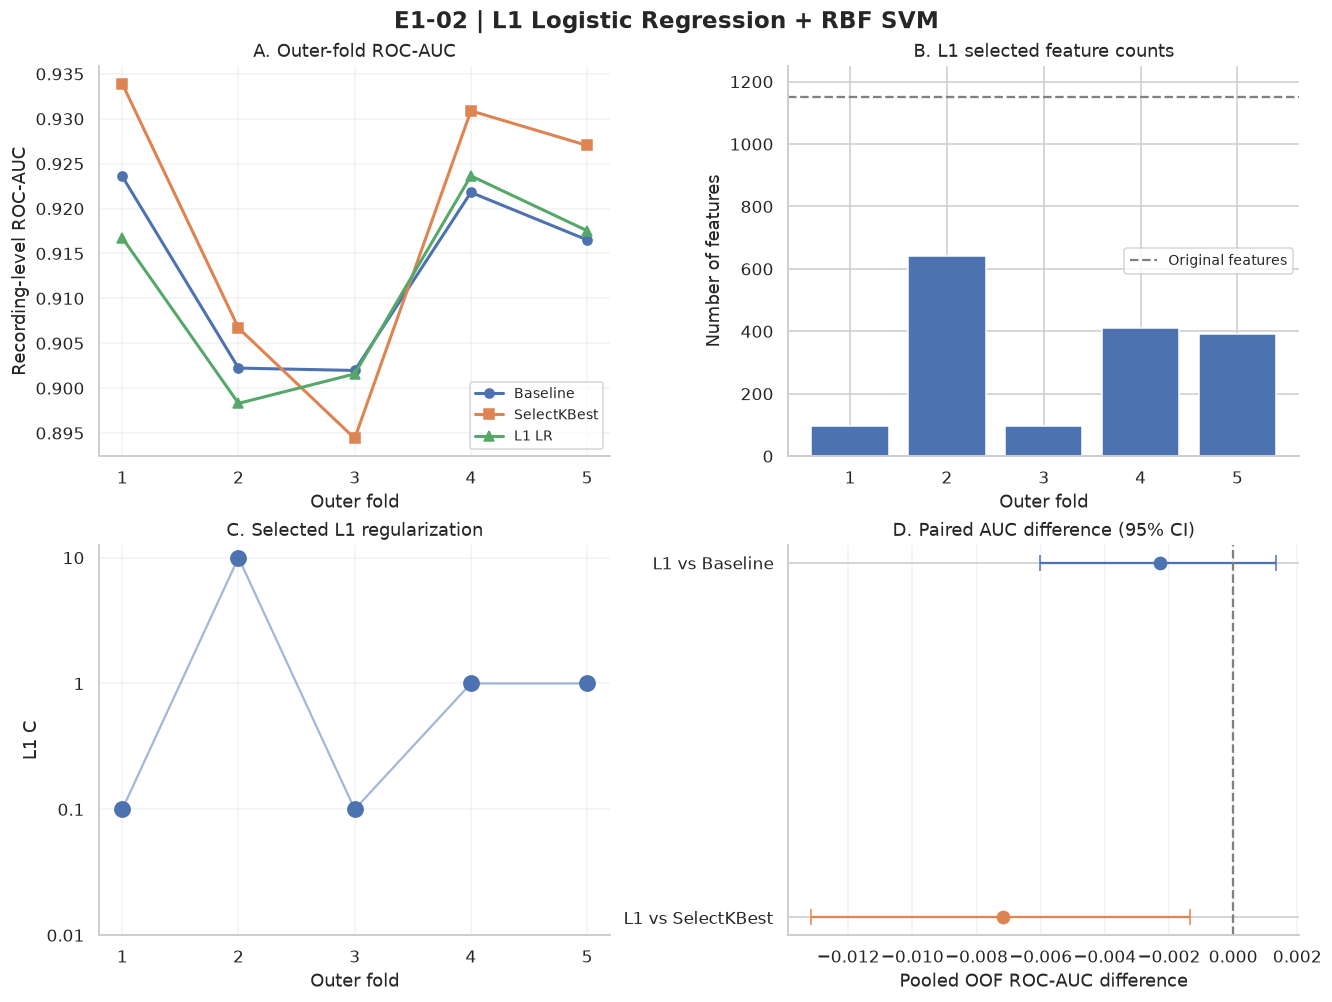

Figures saved:
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/figures/E1-02_L1_Results.png
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/reports/feature_selection/figures/E1-02_L1_Results.pdf


In [26]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    2, 2, figsize=(12, 9),
    constrained_layout=True
)

folds = l1_results_df["fold"].to_numpy()

# A — Outer-fold ROC-AUC
ax = axes[0, 0]

ax.plot(
    folds,
    baseline_results_df.sort_values("fold")["roc_auc"],
    marker="o",
    linewidth=2,
    label="Baseline"
)

ax.plot(
    folds,
    selectkbest_results_df.sort_values("fold")["roc_auc"],
    marker="s",
    linewidth=2,
    label="SelectKBest"
)

ax.plot(
    folds,
    l1_results_df.sort_values("fold")["roc_auc"],
    marker="^",
    linewidth=2,
    label="L1 LR"
)

ax.set(
    title="A. Outer-fold ROC-AUC",
    xlabel="Outer fold",
    ylabel="Recording-level ROC-AUC"
)
ax.set_xticks(folds)
ax.legend(fontsize=9)
ax.grid(alpha=0.25)

# B — Number of selected features
ax = axes[0, 1]

ax.bar(
    folds,
    l1_results_df["n_selected"]
)

ax.axhline(
    1152,
    linestyle="--",
    color="gray",
    label="Original features"
)

ax.set(
    title="B. L1 selected feature counts",
    xlabel="Outer fold",
    ylabel="Number of features"
)
ax.set_xticks(folds)
ax.set_ylim(0, 1250)
ax.legend(fontsize=9)

# C — Selected L1 regularization
ax = axes[1, 0]

ax.scatter(
    folds,
    l1_results_df["best_l1_C"],
    s=100
)

ax.plot(
    folds,
    l1_results_df["best_l1_C"],
    alpha=0.5
)

ax.set_yscale("log")
ax.set_yticks([0.01, 0.1, 1, 10])
ax.set_yticklabels(["0.01", "0.1", "1", "10"])

ax.set(
    title="C. Selected L1 regularization",
    xlabel="Outer fold",
    ylabel="L1 C"
)
ax.set_xticks(folds)
ax.grid(alpha=0.25)

# D — Paired pooled OOF AUC differences
ax = axes[1, 1]

comparisons = l1_comparison_df.reset_index(drop=True)

for i, row in comparisons.iterrows():
    ax.errorbar(
        row["auc_difference"],
        i,
        xerr=[[
            row["auc_difference"] - row["ci_lower"]
        ], [
            row["ci_upper"] - row["auc_difference"]
        ]],
        fmt="o",
        capsize=5,
        markersize=8
    )

ax.axvline(
    0,
    color="gray",
    linestyle="--"
)

ax.set_yticks(range(len(comparisons)))
ax.set_yticklabels(comparisons["comparison"])
ax.invert_yaxis()

ax.set(
    title="D. Paired AUC difference (95% CI)",
    xlabel="Pooled OOF ROC-AUC difference"
)
ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "E1-02 | L1 Logistic Regression + RBF SVM",
    fontsize=15,
    fontweight="bold"
)

figure_path = FIGURE_DIR / "E1-02_L1_Results"

fig.savefig(
    figure_path.with_suffix(".png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_path.with_suffix(".pdf"),
    bbox_inches="tight"
)

plt.show()

print("Figures saved:")
print(figure_path.with_suffix(".png"))
print(figure_path.with_suffix(".pdf"))


## 21. Configure RFE + RBF SVM

In [27]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

import numpy as np
import pandas as pd
import json
import time

rfe_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),

    ("selector", RFE(
        estimator=LogisticRegression(
            penalty="l2",
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        n_features_to_select=200,
        step=0.2,
    )),

    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=False,
        cache_size=500,
        random_state=RANDOM_STATE,
    )),
])

rfe_param_grid = {
    "selector__n_features_to_select": [
        50, 100, 200, 500
    ],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": [
        "scale", 0.01, 0.001
    ],
}

n_candidates = (
    len(rfe_param_grid["selector__n_features_to_select"])
    * len(rfe_param_grid["classifier__C"])
    * len(rfe_param_grid["classifier__gamma"])
)

print("Experiment: E1-03")
print("Selector: RFE with L2 Logistic Regression")
print("Classifier: RBF SVM")
print("Original features:", X_train.shape[1])
print("Feature candidates:",
      rfe_param_grid["selector__n_features_to_select"])
print("RFE step:", 0.2)
print("Hyperparameter combinations:", n_candidates)
print("Inner CV fits per outer fold:",
      n_candidates * N_INNER_SPLITS)
print("Total inner CV fits:",
      n_candidates * N_INNER_SPLITS * N_OUTER_SPLITS)
print("Final evaluation enabled:", RUN_FINAL_EVALUATION)


Experiment: E1-03
Selector: RFE with L2 Logistic Regression
Classifier: RBF SVM
Original features: 1152
Feature candidates: [50, 100, 200, 500]
RFE step: 0.2
Hyperparameter combinations: 36
Inner CV fits per outer fold: 180
Total inner CV fits: 900
Final evaluation enabled: False


## 22. Execute E1-03 nested cross-validation

In [28]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

import time
import json
import numpy as np
import pandas as pd

rfe_results = []
rfe_oof_predictions = []
rfe_selected_features = []

for fold_id, (train_idx, test_idx) in enumerate(
    outer_splits, start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_test = X_train.iloc[test_idx]

    y_outer_train = y_train.iloc[train_idx]
    y_outer_test = y_train.iloc[test_idx]

    groups_outer_train = groups_train.iloc[train_idx]

    search = GridSearchCV(
        estimator=clone(rfe_pipeline),
        param_grid=rfe_param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=N_JOBS,
        refit=True,
        error_score="raise",
    )

    start_time = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train,
    )

    elapsed = time.perf_counter() - start_time

    best_model = search.best_estimator_

    scores = best_model.decision_function(
        X_outer_test
    )

    auc = roc_auc_score(
        y_outer_test,
        scores
    )

    selected_mask = (
        best_model.named_steps["selector"]
        .get_support()
    )

    selected_names = np.asarray(
        FEATURE_COLS
    )[selected_mask]

    rfe_results.append({
        "fold": fold_id,
        "roc_auc": auc,
        "best_n_features": search.best_params_[
            "selector__n_features_to_select"
        ],
        "best_svm_C": search.best_params_[
            "classifier__C"
        ],
        "best_gamma": search.best_params_[
            "classifier__gamma"
        ],
        "inner_cv_auc": search.best_score_,
        "n_selected": len(selected_names),
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "runtime_seconds": elapsed,
    })

    rfe_oof_predictions.append(
        pd.DataFrame({
            "fold": fold_id,
            "filepath": e1_train.iloc[test_idx][
                "filepath"
            ].to_numpy(),
            "patient_id": groups_train.iloc[
                test_idx
            ].to_numpy(),
            "y_true": y_outer_test.to_numpy(),
            "score": scores,
        })
    )

    rfe_selected_features.append({
        "fold": fold_id,
        "n_features": len(selected_names),
        "features": selected_names.tolist(),
    })

    print(
        f"Fold {fold_id}: "
        f"AUC={auc:.4f} | "
        f"Features={len(selected_names)} | "
        f"SVM C={search.best_params_['classifier__C']} | "
        f"gamma={search.best_params_['classifier__gamma']} | "
        f"time={elapsed:.1f}s",
        flush=True,
    )

rfe_results_df = pd.DataFrame(rfe_results)

rfe_oof_df = pd.concat(
    rfe_oof_predictions,
    ignore_index=True
)

# Integrity checks
assert len(rfe_oof_df) == len(X_train)
assert rfe_oof_df["filepath"].is_unique

assert (
    rfe_oof_df.groupby("patient_id")["fold"].nunique()
    == 1
).all()

assert (
    rfe_results_df["n_selected"]
    == rfe_results_df["best_n_features"]
).all()

print("\nE1-03 Nested CV Results")
display(rfe_results_df)

print(
    "\nMean outer-fold ROC-AUC:",
    round(rfe_results_df["roc_auc"].mean(), 4)
)

print(
    "Std outer-fold ROC-AUC:",
    round(rfe_results_df["roc_auc"].std(), 4)
)

print(
    "Mean selected features:",
    round(rfe_results_df["n_selected"].mean(), 1)
)

print(
    "Total runtime (minutes):",
    round(rfe_results_df["runtime_seconds"].sum() / 60, 2)
)

# Save results
rfe_results_df.to_csv(
    OUTPUT_DIRS["nested_cv"] / "E1-03_outer_results.csv",
    index=False,
)

rfe_oof_df.to_parquet(
    OUTPUT_DIRS["nested_cv"] / "E1-03_oof_predictions.parquet",
    index=False,
)

with open(
    OUTPUT_DIRS["selection"] / "E1-03_selected_features.json",
    "w"
) as f:
    json.dump(rfe_selected_features, f, indent=2)

print("\nE1-03 results saved successfully.")


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

Fold 1: AUC=0.9213 | Features=200 | SVM C=1.0 | gamma=scale | time=248.2s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model

Fold 2: AUC=0.8994 | Features=500 | SVM C=1.0 | gamma=scale | time=261.6s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

...

Fold 4: AUC=0.9169 | Features=500 | SVM C=1.0 | gamma=0.001 | time=279.1s


/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

Fold 5: AUC=0.9162 | Features=500 | SVM C=1.0 | gamma=scale | time=268.4s

E1-03 Nested CV Results


,fold,roc_auc,best_n_features,best_svm_C,best_gamma,inner_cv_auc,n_selected,n_train,n_test,runtime_seconds
0,1,0.921262,200,1.0,scale,0.908931,200,1731,434,248.235528
1,2,0.899405,500,1.0,scale,0.912150,500,1731,434,261.613040
2,3,0.893326,500,10.0,0.001,0.918639,500,1733,432,264.130721
3,4,0.916908,500,1.0,0.001,0.909384,500,1733,432,279.085143
4,5,0.916187,500,1.0,scale,0.909585,500,1732,433,268.434787



Mean outer-fold ROC-AUC: 0.9094
Std outer-fold ROC-AUC: 0.0123
Mean selected features: 440.0
Total runtime (minutes): 22.02

E1-03 results saved successfully.
